# Étape 3 — Préparation des données

Projet Python for AI — ciblage d'une campagne de télémarketing bancaire.
M1 ISA, Université de Tours.

Ce notebook reprend la fin de la chaîne du TD2 (`analyze_correlations`,
`standard_scaling`, `save_data_and_parameters`) et prépare le passage au TD3.
Il produit `sorties/output.csv` et `sorties/params.pkl`, selon le contrat de
passage de relais du TD2 vers le TD3.

Les décisions de préparation s'appuient sur l'étape 2 (`01_exploration.ipynb`)
et sur l'état de l'art (`references/etat_de_lart.md`).

In [1]:
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from outils import bold, cyan, print_step, print_title

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 60)

FICHIER = '../data/bank-additional-full.csv'
DOSSIER_FIGURES = '../figures/'
DOSSIER_SORTIES = '../sorties/'
TARGET_COL = 'y'
FUITE_COL = 'duration'
SEUIL_UNKNOWN = 0.01      # au-dela : modalite a part ; en dessous : imputation
SEUIL_CORR = 0.65         # seuil du TD2
RANDOM_STATE = 42

## 1. Chargement et retrait de la variable de fuite

`duration` est la durée du dernier appel. Elle n'est connue qu'une fois l'appel
terminé : l'utiliser pour décider *qui appeler* est impossible. Les auteurs du
jeu le signalent explicitement, et l'étape 2 a mesuré son effet (+0,1586 de
ROC-AUC à elle seule).

Elle est retirée ici, une fois pour toutes, de façon que plus aucune cellule en
aval ne puisse l'utiliser par accident.

In [2]:
df = pd.read_csv(filepath_or_buffer=FICHIER, delimiter=';')
print_title(FICHIER)
print_step('Jeu brut')
print(bold('Dimensions : ') + f'{df.shape[0]} lignes, {df.shape[1]} colonnes')

df = df.drop(columns=[FUITE_COL])
print_step(f'Retrait de la variable de fuite « {FUITE_COL} »')
print(bold('Dimensions apres retrait : ')
      + f'{df.shape[0]} lignes, {df.shape[1]} colonnes')
print(bold('Variables restantes : '))
print(list(df.columns))


--------------------------------------------------------------------------------
Fichier : : ../data/bank-additional-full.csv
--------------------------------------------------------------------------------

*** Jeu brut ***

Dimensions : 41188 lignes, 21 colonnes

*** Retrait de la variable de fuite « duration » ***

Dimensions apres retrait : 41188 lignes, 20 colonnes
Variables restantes : 
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


## 2. Recodage des variables d'historique

L'étape 2 a établi que la sentinelle `pdays = 999` recouvre **deux situations
incompatibles**, et que `previous` est la variable fiable pour savoir si un
client a déjà été contacté (`previous == 0` coïncide exactement avec
`poutcome == 'nonexistent'`, sans aucun désaccord sur 41 188 lignes).

Le recodage sépare donc ce que la sentinelle confondait :

| Variable créée | Contenu |
| --- | --- |
| `deja_contacte` | 1 si `previous ≥ 1`, construit sur `previous` et non sur `pdays` |
| `pdays_statut` | `delai_connu` / `delai_inconnu` / `sans_objet` |
| `delai_dernier_contact` | le délai réel, 0 quand il n'est pas défini — la valeur 0 n'est interprétable qu'en lisant `pdays_statut` |

`pdays` est ensuite supprimée : toute son information est répartie dans ces
trois variables, et la conserver réintroduirait la sentinelle 999 dans le
calcul des corrélations et de la normalisation.

In [3]:
print_step("Recodage des variables d'historique")

df['deja_contacte'] = (df['previous'] >= 1).astype(int)

statut = np.where(df['pdays'] != 999, 'delai_connu',
                  np.where(df['previous'] >= 1, 'delai_inconnu', 'sans_objet'))
df['pdays_statut'] = statut

df['delai_dernier_contact'] = df['pdays'].where(df['pdays'] != 999, 0)

print(bold('Repartition de pdays_statut :'))
repartition = df['pdays_statut'].value_counts()
y_bin = (df[TARGET_COL] == 'yes')
for modalite, effectif in repartition.items():
    masque = df['pdays_statut'] == modalite
    print(f'  {modalite:15s} n = {effectif:6d}   '
          + f'taux de souscription = {100 * y_bin[masque].mean():5.2f} %')
print(bold('\nBase de reference : ') + f'{100 * y_bin.mean():.2f} %')

df = df.drop(columns=['pdays'])
print(bold('\npdays supprimee. ')
      + 'Son information est portee par pdays_statut et delai_dernier_contact.')


*** Recodage des variables d'historique ***

Repartition de pdays_statut :
  sans_objet      n =  35563   taux de souscription =  8.83 %
  delai_inconnu   n =   4110   taux de souscription = 12.94 %
  delai_connu     n =   1515   taux de souscription = 63.83 %

Base de reference : 11.27 %

pdays supprimee. Son information est portee par pdays_statut et delai_dernier_contact.


## 3. Traitement des valeurs `"unknown"`

L'étape 2 a montré que `df.isna().sum()` renvoie 0 alors que six variables
portent des valeurs manquantes encodées `"unknown"`, dans des proportions très
différentes — de 0,19 % à 20,87 %.

Jin & He (2019), qui travaillent sur ce même jeu, traitent les manquants
**selon deux méthodes différentes suivant le nombre d'observations
concernées**. Nous reprenons ce principe avec un seuil explicite de 1 % :

- **au-dessus de 1 %** → `"unknown"` est conservé comme **modalité à part
  entière**. À ces volumes, imputer reviendrait à inventer une information pour
  des milliers de clients ; et l'étape 2 a montré que le fait même de ne pas
  savoir est informatif ;
- **en dessous de 1 %** → imputation par le mode. Le volume est trop faible
  pour qu'une modalité dédiée soit estimable, et trop faible pour que
  l'imputation biaise quoi que ce soit.

In [4]:
print_step('Inventaire des valeurs « unknown »')

colonnes_cat = df.select_dtypes(include='object').columns.drop(TARGET_COL)
inventaire = []
for col in colonnes_cat:
    n = int((df[col] == 'unknown').sum())
    if n:
        inventaire.append((col, n, 100 * n / len(df)))

resume_unknown = pd.DataFrame(inventaire,
                              columns=['variable', 'effectif', 'pourcentage'])
resume_unknown['traitement'] = np.where(
    resume_unknown['pourcentage'] / 100 >= SEUIL_UNKNOWN,
    'modalite a part', 'imputation par le mode')
print(resume_unknown.to_string(index=False))

print_step('Mecanisme de manquement : housing et loan')
print(bold('unknown sur housing : ') + f"{int((df.housing == 'unknown').sum())}")
print(bold('unknown sur loan    : ') + f"{int((df.loan == 'unknown').sum())}")
simultanes = ((df.housing == 'unknown') & (df.loan == 'unknown')).sum()
print(bold('unknown sur les deux simultanement : ') + f'{int(simultanes)}')


*** Inventaire des valeurs « unknown » ***



 variable  effectif  pourcentage             traitement
      job       330     0.801204 imputation par le mode
  marital        80     0.194231 imputation par le mode
education      1731     4.202680        modalite a part
  default      8597    20.872584        modalite a part
  housing       990     2.403613        modalite a part
     loan       990     2.403613        modalite a part

*** Mecanisme de manquement : housing et loan ***

unknown sur housing : 990
unknown sur loan    : 990
unknown sur les deux simultanement : 990


Les manquants de `housing` et `loan` sont **exactement les mêmes lignes**. Ce
n'est donc pas un manquement aléatoire variable par variable : c'est un défaut
de saisie *structurel*, probablement une interrogation du système de crédit qui
a échoué pour ces clients. Les deux variables manquent ensemble ou pas du tout.

Cette information est elle-même exploitable, et elle justifie de conserver
`"unknown"` plutôt que de l'imputer : le modèle peut apprendre que l'absence de
renseignement de crédit caractérise un certain type de dossier.

In [5]:
print_step('Application du traitement')

for _, ligne in resume_unknown.iterrows():
    col = ligne['variable']
    if ligne['pourcentage'] / 100 >= SEUIL_UNKNOWN:
        print(f'  {col:12s} conservee avec la modalite « unknown » '
              + f"({ligne['pourcentage']:.2f} %)")
    else:
        mode = df.loc[df[col] != 'unknown', col].mode()[0]
        n = int((df[col] == 'unknown').sum())
        df[col] = df[col].replace('unknown', mode)
        print(f'  {col:12s} {n} valeurs imputees par le mode « {mode} »')

print(bold('\nunknown restants : ')
      + f"{int(sum((df[c] == 'unknown').sum() for c in colonnes_cat))}")


*** Application du traitement ***



  job          330 valeurs imputees par le mode « admin. »
  marital      80 valeurs imputees par le mode « married »
  education    conservee avec la modalite « unknown » (4.20 %)
  default      conservee avec la modalite « unknown » (20.87 %)
  housing      conservee avec la modalite « unknown » (2.40 %)
  loan         conservee avec la modalite « unknown » (2.40 %)



unknown restants : 12308


## 4. Modalités à très faible effectif

Deux modalités sont trop peu représentées pour qu'un modèle en estime l'effet :
`education = illiterate` (18 observations) et `default = yes` (3 observations).

Les deux cas ne se traitent pas de la même façon, et c'est un arbitrage à
assumer :

- **`education = illiterate` est regroupée avec `basic.4y`.** Le regroupement
  est sémantiquement cohérent : ce sont les deux niveaux de formation les plus
  bas, et l'échelle de `education` est ordonnée.
- **`default = yes` est conservée telle quelle.** La seule fusion
  volumétriquement envisageable serait avec `unknown`, ce qui reviendrait à
  confondre « ce client est en défaut de paiement » avec « on ne sait pas s'il
  l'est ». Les deux ne signifient pas la même chose. Nous préférons une
  modalité inutile à une modalité trompeuse : avec 3 observations, le modèle
  n'en tirera rien, mais rien de faux non plus.

In [6]:
print_step('Regroupement des faibles effectifs')

n_illettres = int((df['education'] == 'illiterate').sum())
df['education'] = df['education'].replace('illiterate', 'basic.4y')
print(f"  education : {n_illettres} 'illiterate' regroupes avec 'basic.4y'")

print(f"  default   : {int((df['default'] == 'yes').sum())} 'yes' conserves "
      + '(fusion avec unknown semantiquement inacceptable)')

print(bold('\nEffectifs des modalites apres regroupement :'))
for col in ['education', 'default']:
    print(f'  {col} : ' + str(df[col].value_counts().to_dict()))


*** Regroupement des faibles effectifs ***



  education : 18 'illiterate' regroupes avec 'basic.4y'
  default   : 3 'yes' conserves (fusion avec unknown semantiquement inacceptable)

Effectifs des modalites apres regroupement :
  education : {'university.degree': 12168, 'high.school': 9515, 'basic.9y': 6045, 'professional.course': 5243, 'basic.4y': 4194, 'basic.6y': 2292, 'unknown': 1731}
  default : {'no': 32588, 'unknown': 8597, 'yes': 3}


## 5. Matrice de corrélation

Fonction `analyze_correlations` du TD2, avec son seuil de 0,65. Elle est
appliquée aux variables numériques, l'encodage des catégorielles n'étant pas
encore fait.

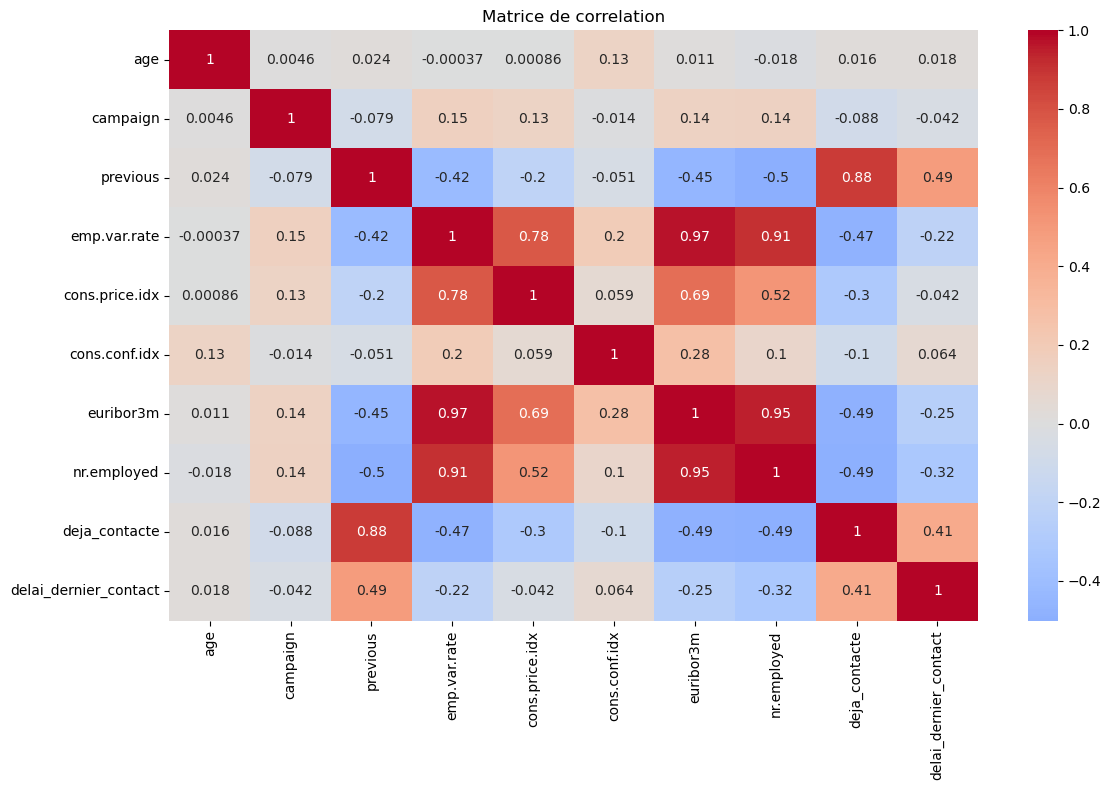


*** Matrice des correlations ***

                        age  campaign  previous  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed  deja_contacte  delai_dernier_contact
age                    1.00      0.00      0.02         -0.00            0.00           0.13       0.01        -0.02           0.02                   0.02
campaign               0.00      1.00     -0.08          0.15            0.13          -0.01       0.14         0.14          -0.09                  -0.04
previous               0.02     -0.08      1.00         -0.42           -0.20          -0.05      -0.45        -0.50           0.88                   0.49
emp.var.rate          -0.00      0.15     -0.42          1.00            0.78           0.20       0.97         0.91          -0.47                  -0.22
cons.price.idx         0.00      0.13     -0.20          0.78            1.00           0.06       0.69         0.52          -0.30                  -0.04
cons.conf.idx          0.13     -0.

In [7]:
def analyze_correlations(df, bound, fig_name, transparent=False):
    """
    Calcule et visualise la matrice de correlation.
    Fonction de la correction du TD2 ; seul le chemin de la figure est
    parametre, pour ecrire dans le dossier figures du projet.
    """
    corr_matrix = df.corr()
    plt.figure(figsize=(12, 8))
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
    plt.title('Matrice de correlation')
    plt.tight_layout()
    plt.savefig(fig_name, dpi=100, transparent=transparent)
    plt.show()
    print_step('Matrice des correlations')
    print(corr_matrix.round(2))
    print('\n' + bold(f'Correlations superieures a {bound} :'))
    fortes_correlations = np.where(np.abs(corr_matrix) >= bound)
    paires = []
    for i, j in zip(*fortes_correlations):
        if i != j and i < j:
            print(f'{corr_matrix.index[i]} et {corr_matrix.columns[j]} : '
                  f'{corr_matrix.iloc[i, j]:.2f}')
            paires.append((corr_matrix.index[i], corr_matrix.columns[j],
                           round(float(corr_matrix.iloc[i, j]), 3)))
    return corr_matrix, paires


colonnes_num = df.select_dtypes(include=[np.number]).columns
corr_matrix, paires_fortes = analyze_correlations(
    df[colonnes_num], SEUIL_CORR, DOSSIER_FIGURES + 'correlations.png')

Six paires dépassent le seuil de 0,65, et elles se répartissent en **deux
blocs** de nature très différente.

**Le bloc macroéconomique** : `euribor3m`, `emp.var.rate`, `nr.employed` et
`cons.price.idx` mesurent le même phénomène — la conjoncture — à des échelles
différentes, et sont corrélés jusqu'à 0,97.

Ils ne sont **pas** supprimés. Une colinéarité forte gêne l'interprétation des
coefficients d'un modèle linéaire, mais ne dégrade pas le pouvoir prédictif, et
les modèles à base d'arbres y sont insensibles. Nous les conservons et nous en
tiendrons compte à la lecture des coefficients, plutôt que de jeter de
l'information en amont.

**La paire `previous` / `deja_contacte` (0,88)** est d'une autre nature : elle
est de notre fait. `deja_contacte` a été construite en section 2 à partir de
`previous`, et la corrélation ne fait que le constater. Les deux ne sont
cependant pas équivalentes : `previous` compte les contacts, `deja_contacte`
marque le seuil entre zéro et au moins un — et l'étape 2 a montré que c'est ce
seuil, et non le compte, qui sépare les populations. Nous conservons les deux et
l'étape 4 tranchera par la sélection de variables, comme le fait le `RFECV` du
TD3.

À noter enfin que l'étape 2 a montré que le bloc macroéconomique encode **la
période** de la campagne : le taux de souscription passe de 2,9 % au début du
fichier à 50,7 % à la fin, pendant que l'Euribor chute de 5,0 à 0,63. C'est
l'objet de la section 8.

## 6. Encodage des variables catégorielles

Tekouabou et al. (2019) prétraitent **séparément chaque type de variable**, et
Jin & He (2019) codent les catégorielles **selon deux méthodes différentes
suivant qu'elles sont ordonnées ou non**. Nous reprenons cette distinction, qui
évite deux erreurs symétriques : perdre un ordre qui existe, ou inventer un
ordre qui n'existe pas.

| Type | Variables | Encodage |
| --- | --- | --- |
| Ordonnées | `education`, `month`, `day_of_week` | ordinal, selon leur ordre naturel |
| Nominales | `job`, `marital`, `default`, `housing`, `loan`, `contact`, `poutcome`, `pdays_statut` | one-hot |

Cas particulier d'`education` : l'échelle est ordonnée, mais `"unknown"` n'a
pas de place dans cet ordre. Nous lui attribuons le niveau médian et nous
ajoutons un indicateur `education_inconnue`, ce qui préserve l'ordre sans
prétendre savoir.

In [8]:
print_step('Encodage des variables ordonnees')

ordre_education = ['basic.4y', 'basic.6y', 'basic.9y', 'high.school',
                   'professional.course', 'university.degree']
ordre_mois = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov',
              'dec']
ordre_jours = ['mon', 'tue', 'wed', 'thu', 'fri']

df['education_inconnue'] = (df['education'] == 'unknown').astype(int)
niveau_median = int(np.median(range(len(ordre_education))))
table_education = {m: i for i, m in enumerate(ordre_education)}
table_education['unknown'] = niveau_median
df['education'] = df['education'].map(table_education)
print(f'  education   : {len(ordre_education)} niveaux ordonnes, '
      + f"'unknown' place au niveau median ({niveau_median}) "
      + f"+ indicateur dedie ({int(df['education_inconnue'].sum())} clients)")

table_mois = {m: i for i, m in enumerate(ordre_mois)}
df['month'] = df['month'].map(table_mois)
print(f'  month       : {len(ordre_mois)} modalites, ordre calendaire')

table_jours = {j: i for i, j in enumerate(ordre_jours)}
df['day_of_week'] = df['day_of_week'].map(table_jours)
print(f'  day_of_week : {len(ordre_jours)} modalites, ordre de la semaine')

assert df[['education', 'month', 'day_of_week']].isna().sum().sum() == 0


*** Encodage des variables ordonnees ***

  education   : 6 niveaux ordonnes, 'unknown' place au niveau median (2) + indicateur dedie (1731 clients)
  month       : 10 modalites, ordre calendaire
  day_of_week : 5 modalites, ordre de la semaine


In [9]:
print_step('Encodage des variables nominales (one-hot)')

colonnes_nominales = [c for c in df.select_dtypes(include='object').columns
                      if c != TARGET_COL]
print(bold('Variables concernees : ') + str(colonnes_nominales))

avant = df.shape[1]
df = pd.get_dummies(df, columns=colonnes_nominales, drop_first=False,
                    dtype=int)
print(bold('\nColonnes : ') + f'{avant} -> {df.shape[1]}')

y = (df[TARGET_COL] == 'yes').astype(int)
X = df.drop(columns=[TARGET_COL])
print(bold('Matrice explicative : ') + f'{X.shape[0]} lignes, {X.shape[1]} colonnes')
print(bold('Cible : ') + f'{int(y.sum())} souscriptions ({100 * y.mean():.2f} %)')


*** Encodage des variables nominales (one-hot) ***

Variables concernees : ['job', 'marital', 'default', 'housing', 'loan', 'contact', 'poutcome', 'pdays_statut']

Colonnes : 23 -> 46


Matrice explicative : 41188 lignes, 45 colonnes
Cible : 4640 souscriptions (11.27 %)


## 7. Normalisation

Fonction `standard_scaling` du TD2. Un seul écart par rapport à la correction :
elle affichait `df.head(10)` sous le libellé « après scaling », ce qui montrait
les données *avant* normalisation. Corrigé en `df_scaled.head(10)`.

Les colonnes issues du one-hot sont déjà dans l'intervalle [0, 1] ; les
normaliser aussi est sans effet sur les modèles mais rendrait les coefficients
moins lisibles. La normalisation ne porte donc que sur les variables
continues d'origine.

In [10]:
def standard_scaling(df, colonnes):
    """
    Normalisation centree-reduite.
    Fonction de la correction du TD2 ; la liste des colonnes est parametree
    (le one-hot ne doit pas etre normalise) et l'apercu affiche bien
    df_scaled et non df.
    """
    scaler = StandardScaler()
    df_scaled = df.copy()
    df_scaled[colonnes] = scaler.fit_transform(df[colonnes])
    print_step('Normalisation des donnees')
    print('\n' + bold('Apercu des donnees apres scaling :'))
    print(df_scaled[colonnes].head(10))
    print('\n' + bold('Statistiques descriptives :'))
    print(df_scaled[colonnes].describe().round(3))
    return scaler, df_scaled


colonnes_continues = ['age', 'campaign', 'previous', 'delai_dernier_contact',
                      'education', 'month', 'day_of_week',
                      'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
                      'euribor3m', 'nr.employed']
scaler, X = standard_scaling(X, colonnes_continues)


*** Normalisation des donnees ***


Apercu des donnees apres scaling :
        age  campaign  previous  delai_dernier_contact  education     month  day_of_week  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed
0  1.533034 -0.565922 -0.349494              -0.164012  -1.921443 -0.787808    -1.402469      0.648092        0.722722       0.886447    0.71246      0.33168
1  1.628993 -0.565922 -0.349494              -0.164012  -0.069498 -0.787808    -1.402469      0.648092        0.722722       0.886447    0.71246      0.33168
2 -0.290186 -0.565922 -0.349494              -0.164012  -0.069498 -0.787808    -1.402469      0.648092        0.722722       0.886447    0.71246      0.33168
3 -0.002309 -0.565922 -0.349494              -0.164012  -1.304128 -0.787808    -1.402469      0.648092        0.722722       0.886447    0.71246      0.33168
4  1.533034 -0.565922 -0.349494              -0.164012  -0.069498 -0.787808    -1.402469      0.648092        0.722722       0.886447    0

             age   campaign   previous  delai_dernier_contact  education      month  day_of_week  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  \
count  41188.000  41188.000  41188.000              41188.000  41188.000  41188.000    41188.000     41188.000       41188.000      41188.000  41188.000   
mean      -0.000     -0.000      0.000                  0.000      0.000      0.000        0.000         0.000          -0.000         -0.000      0.000   
std        1.000      1.000      1.000                  1.000      1.000      1.000        1.000         1.000           1.000          1.000      1.000   
min       -2.209     -0.566     -0.349                 -0.164     -1.921     -1.768       -1.402        -2.216          -2.375         -2.225     -1.722   
25%       -0.770     -0.566     -0.349                 -0.164     -0.687     -0.788       -0.694        -1.198          -0.865         -0.475     -1.313   
50%       -0.194     -0.205     -0.349                 -0.164   

## 8. Deux protocoles de découpage

C'est le point méthodologique central de ce notebook.

L'article fondateur du jeu (Moro, Cortez & Rita, 2014) entraîne **sur les
données antérieures à juillet 2012** et évalue **sur les postérieures**, en
fenêtre glissante. Les travaux ultérieurs sur ce même jeu (Tekouabou 2018 et
2019, Ilham 2019, Jiang 2022) sont revenus au découpage aléatoire.

Or le fichier est **ordonné chronologiquement** et couvre la crise financière.
Un découpage aléatoire répartit les deux régimes macroéconomiques de part et
d'autre, et le modèle peut apprendre « euribor3m bas ⇒ probablement oui ». La
performance mesurée vient alors en partie de l'identification de la **période**,
non de la caractérisation du **client**.

Les deux découpages sont donc calculés et conservés, pour que l'étape 4 puisse
mesurer l'écart. Ce n'est pas de la modélisation de série temporelle : il n'y a
ni autorégression, ni saisonnalité, ni prévision à horizon. C'est une question
de conception du protocole de validation.

**Le rééquilibrage n'est pas appliqué ici.** La correction du TD3 enchaîne
`rebalance_classes` puis `split_data` ; dans cet ordre, SMOTE fabrique des
points synthétiques à partir de voisins qui se retrouvent ensuite répartis
entre apprentissage et test, ce qui rend le score de test optimiste. Le
rééquilibrage est donc reporté au notebook 03, **après** le découpage et **sur
le seul jeu d'apprentissage**.

In [11]:
def split_data(X, y, test_size=0.2, val_size=0.2, random_state=42):
    """
    Decoupage aleatoire stratifie en apprentissage / validation / test.
    Reprend la fonction du TD3, en retournant les index afin que les deux
    protocoles de decoupage soient comparables.
    """
    idx = np.arange(len(y))
    idx_tmp, idx_test = train_test_split(
        idx, test_size=test_size, random_state=random_state, stratify=y)
    idx_train, idx_val = train_test_split(
        idx_tmp, test_size=val_size, random_state=random_state,
        stratify=y.iloc[idx_tmp])
    return idx_train, idx_val, idx_test


def split_chronologique(y, part_train=0.6, part_val=0.2):
    """
    Decoupage par position dans le fichier, qui est en ordre chronologique.
    L'apprentissage porte sur le passe, le test sur le futur.
    """
    n = len(y)
    fin_train = int(n * part_train)
    fin_val = int(n * (part_train + part_val))
    idx = np.arange(n)
    return idx[:fin_train], idx[fin_train:fin_val], idx[fin_val:]


decoupages = {
    'aleatoire': split_data(X, y, random_state=RANDOM_STATE),
    'chronologique': split_chronologique(y),
}

print_step('Comparaison des deux protocoles de decoupage')
lignes = []
for nom, (i_tr, i_va, i_te) in decoupages.items():
    for libelle, idx in [('apprentissage', i_tr), ('validation', i_va),
                         ('test', i_te)]:
        lignes.append((nom, libelle, len(idx),
                       round(100 * y.iloc[idx].mean(), 2)))

comparaison = pd.DataFrame(lignes, columns=['protocole', 'jeu', 'n',
                                            'taux_souscription_%'])
print(comparaison.to_string(index=False))


*** Comparaison des deux protocoles de decoupage ***

    protocole           jeu     n  taux_souscription_%
    aleatoire apprentissage 26360                11.27
    aleatoire    validation  6590                11.26
    aleatoire          test  8238                11.26
chronologique apprentissage 24712                 4.81
chronologique    validation  8238                11.07
chronologique          test  8238                30.83


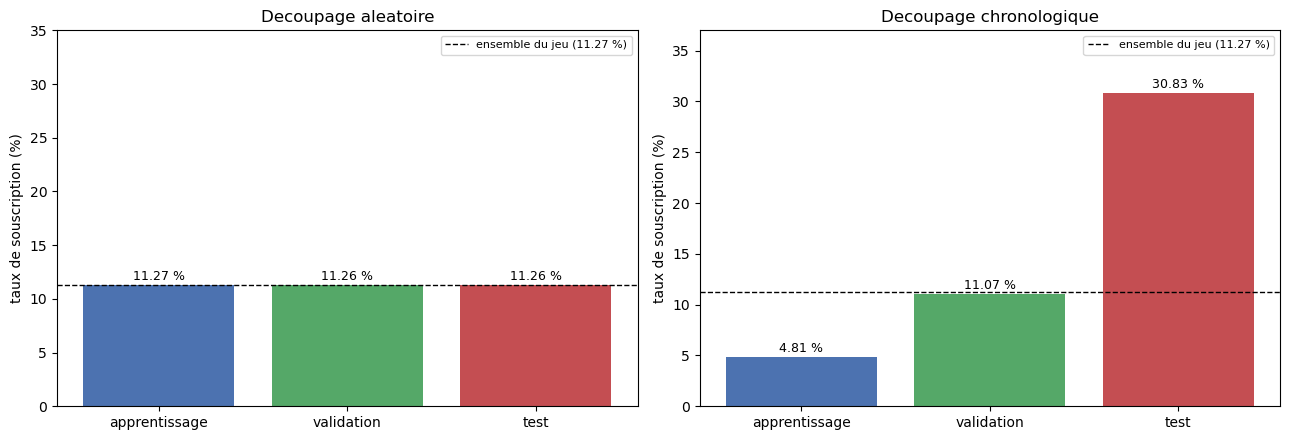

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (nom, (i_tr, i_va, i_te)) in zip(axes, decoupages.items()):
    taux = [100 * y.iloc[i].mean() for i in (i_tr, i_va, i_te)]
    barres = ax.bar(['apprentissage', 'validation', 'test'], taux,
                    color=['#4C72B0', '#55A868', '#C44E52'])
    ax.axhline(100 * y.mean(), color='black', linestyle='--', linewidth=1,
               label=f'ensemble du jeu ({100 * y.mean():.2f} %)')
    ax.set_title(f'Decoupage {nom}')
    ax.set_ylabel('taux de souscription (%)')
    ax.set_ylim(0, max(35, max(taux) * 1.2))
    ax.legend(fontsize=8)
    for barre, valeur in zip(barres, taux):
        ax.text(barre.get_x() + barre.get_width() / 2, valeur + 0.5,
                f'{valeur:.2f} %', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES + 'decoupages.png', dpi=100)
plt.show()

Le contraste est le résultat le plus important de cette étape.

Le découpage **aléatoire** donne trois jeux au même taux de souscription, à la
décimale près : tout va bien en apparence. Le découpage **chronologique** donne
un jeu d'apprentissage et un jeu de test aux taux radicalement différents,
parce qu'ils correspondent à des régimes économiques différents.

C'est la situation réelle d'exploitation : on entraîne sur le passé et on
prédit sur l'avenir. Le découpage aléatoire masque cette difficulté au lieu de
la mesurer — et c'est, très probablement, une partie de l'explication des
performances étonnamment élevées rapportées par certains travaux du corpus.

## 9. Sauvegarde

Fonction `save_data_and_parameters` du TD2, qui produit le couple
`output.csv` + `params.pkl` attendu par le TD3.

`output.csv` conserve **l'ordre d'origine des lignes**, sans quoi le découpage
chronologique ne serait plus reproductible. Les index des deux découpages sont
enregistrés dans `params.pkl`, ainsi que les tables d'encodage, afin que le
notebook 03 n'ait aucune décision de préparation à reprendre.

In [13]:
def save_data_and_parameters(df, data_file, scaler, param_file, extras=None):
    """
    Sauvegarde des donnees et des parametres de pretraitement.
    Reprend la fonction du TD2 ; le dictionnaire extras permet de transmettre
    au TD3 les index de decoupage et les tables d'encodage.
    """
    print_step('Sauvegarde des donnees')
    df.to_csv(data_file, sep=';', index=False)
    print('\n' + bold('Fichier de donnees : ') + data_file)

    preprocess_params = {
        'scaler_mean_': scaler.mean_,
        'scaler_scale_': scaler.scale_,
    }
    if extras:
        preprocess_params.update(extras)

    print('\n' + bold('Cles enregistrees : '))
    for cle in preprocess_params:
        print(f'  {cle}')

    with open(param_file, 'wb') as f:
        pickle.dump(preprocess_params, f)
    print('\n' + bold('Fichier de parametres : ') + param_file)
    return preprocess_params


sortie = X.copy()
sortie[TARGET_COL] = y.values

params = save_data_and_parameters(
    sortie,
    DOSSIER_SORTIES + 'output.csv',
    scaler,
    DOSSIER_SORTIES + 'params.pkl',
    extras={
        'colonnes_continues': colonnes_continues,
        'colonnes_finales': list(X.columns),
        'table_education': table_education,
        'table_mois': table_mois,
        'table_jours': table_jours,
        'variables_retirees': [FUITE_COL, 'pdays'],
        'seuil_unknown': SEUIL_UNKNOWN,
        'decoupage_aleatoire': {
            'train': decoupages['aleatoire'][0],
            'val': decoupages['aleatoire'][1],
            'test': decoupages['aleatoire'][2],
        },
        'decoupage_chronologique': {
            'train': decoupages['chronologique'][0],
            'val': decoupages['chronologique'][1],
            'test': decoupages['chronologique'][2],
        },
        'reequilibrage': 'reporte au notebook 03, apres decoupage, '
                         'sur le seul jeu d apprentissage',
    })


*** Sauvegarde des donnees ***




Fichier de donnees : ../sorties/output.csv

Cles enregistrees : 
  scaler_mean_
  scaler_scale_
  colonnes_continues
  colonnes_finales
  table_education
  table_mois
  table_jours
  variables_retirees
  seuil_unknown
  decoupage_aleatoire
  decoupage_chronologique
  reequilibrage

Fichier de parametres : ../sorties/params.pkl


In [14]:
print_step("Synthese de l'etape 3")

synthese = pd.DataFrame([
    ('Fuite', f'{FUITE_COL} retiree', 'Connue seulement apres l appel'),
    ('Historique', 'deja_contacte, pdays_statut, delai_dernier_contact',
     'Indicateur bati sur previous ; pdays supprimee'),
    ('Manquants', f"unknown : modalite a part si >= {100 * SEUIL_UNKNOWN:.0f} %, "
                  'sinon imputation par le mode',
     'Principe de Jin & He (2019)'),
    ('Mecanisme', 'housing et loan manquent sur les memes lignes',
     'Manquement structurel, non aleatoire'),
    ('Faibles effectifs', 'illiterate regroupe ; default=yes conservee',
     'Fusion avec unknown semantiquement inacceptable'),
    ('Correlations', f'{len(paires_fortes)} paires au-dela de {SEUIL_CORR}',
     'Bloc macroeconomique conserve'),
    ('Encodage', 'ordinal pour les ordonnees, one-hot pour les nominales',
     'Principe de Tekouabou (2019) et Jin & He (2019)'),
    ('Normalisation', f'{len(colonnes_continues)} variables continues',
     'Le one-hot n est pas normalise'),
    ('Decoupage', 'aleatoire ET chronologique', 'Comparaison a l etape 4'),
    ('Reequilibrage', 'non applique ici',
     'Apres decoupage, sur le train seul : notebook 03'),
    ('Dimensions finales', f'{X.shape[0]} lignes, {X.shape[1]} colonnes',
     f'{100 * y.mean():.2f} % de souscriptions'),
], columns=['etape', 'decision', 'justification'])

print(synthese.to_string(index=False))

synthese.to_csv(DOSSIER_SORTIES + 'etape3_synthese.csv', index=False, sep=';')
comparaison.to_csv(DOSSIER_SORTIES + 'etape3_decoupages.csv', index=False,
                   sep=';')
resume_unknown.to_csv(DOSSIER_SORTIES + 'etape3_unknown.csv', index=False,
                      sep=';')

print_step('Suite')
print('Le notebook 03 lit output.csv et params.pkl, applique les deux')
print('decoupages, reequilibre le seul jeu d apprentissage, puis entraine')
print('et compare les modeles.')


*** Synthese de l'etape 3 ***

             etape                                                          decision                                    justification
             Fuite                                                  duration retiree                   Connue seulement apres l appel
        Historique                deja_contacte, pdays_statut, delai_dernier_contact   Indicateur bati sur previous ; pdays supprimee
         Manquants unknown : modalite a part si >= 1 %, sinon imputation par le mode                      Principe de Jin & He (2019)
         Mecanisme                     housing et loan manquent sur les memes lignes             Manquement structurel, non aleatoire
 Faibles effectifs                       illiterate regroupe ; default=yes conservee  Fusion avec unknown semantiquement inacceptable
      Correlations                                          6 paires au-dela de 0.65                    Bloc macroeconomique conserve
          Encodage            